In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_PATH = Path.cwd().parent
RELATIV_PATH_PROCESSED_DATA = "data/processed/processed_dataset_2023.csv"
RELATIV_PATH_INTERIM_DATA = "data/interim/interim_dataset.csv"

# Relationships between features: Spearman, Pearson, log-log scatter plots

Pairs to measure: health/cap and health % against GDP/cap, log(CO₂) against log(GDP/cap) (Kaya identity), CO₂ against PM2.5.

| Feature | Role | Log | Standardization | Suspected correlation (to be measured) |
|---|---|---|---|---|
| GDP per capita (PPP) | Active | yes | yes, after log | Health spending per capita (contained in its definition), CO₂ per capita (Kaya identity), life expectancy (Preston curve) |
| Life expectancy | Active | no | yes | GDP per capita |
| CO₂ per capita | Active | yes | yes, after log | GDP per capita; PM2.5 (uncertain link: contribution vs. exposure) |
| PM2.5 | Active | yes | yes, after log | CO₂ per capita (to check); little link expected with GDP per capita (desert dust) |
| Urbanization | Active | no | yes | GDP per capita (likely link, but noisy because of how "urban" is defined) |
| Health spending (% of GDP) | Active (to be decided) | no | yes | Weakly linked to GDP per capita (ambiguous); linked to health spending per capita by construction |
| Health spending per capita (created) | Candidate | yes | yes, after log | **Strongly linked to GDP per capita**: log(health per capita) = log(health %) + log(GDP per capita) |
| Population | Illustrative | no | no | Not applicable (excluded from distances) |
| Land area | Illustrative | no | no | Linked to population (worth noting) |
| World Bank region, income group (to be confirmed) | Illustrative (later) | no | no | Not applicable |

**Rule**: the three quantities health % of GDP, health per capita and GDP per capita are not kept together (exact relation in log). Decision in the conclusion of this notebook.

In [2]:
df = pd.read_csv(PROJECT_PATH / RELATIV_PATH_PROCESSED_DATA)

# As decided in the previous notebook (04_feature_distributions)

# New feature
df["health_exp_per_capita"] = df["health_expenditure_percentage_of_gdp_pt_gdp"] / 100 * df["gdp_per_capita_ppp_current_ppp"]


# Micro-state exclusion
MIN_POPULATION = 300000
df = df[df["population_ps"]>=MIN_POPULATION]

df

,name,ref_area,time_period,population_ps,land_area_km2,gdp_per_capita_ppp_current_ppp,life_expectancy_yr,co2_emissions_per_capita_t,pm2_5_exposure_mcg_m3,urban_population_percentage_pt,health_expenditure_percentage_of_gdp_pt_gdp,health_exp_per_capita
0,Afghanistan,AFG,2023,41454761,652230.0,2201.722907,66.035,0.280995,37.948311,25.473053,14.985763,329.944977
1,Angola,AGO,2023,36749906,1246700.0,9753.600468,64.617,0.743839,19.907569,69.851503,2.546929,248.417279
2,Albania,ALB,2023,2411658,27400.0,24822.354309,79.602,1.750912,15.514103,58.210609,7.052403,1750.572460
3,United Arab Emirates,ARE,2023,10483751,71020.0,77955.295176,82.909,18.380482,57.186732,85.668070,4.970951,3875.119525
4,Argentina,ARG,2023,45538401,2736690.0,30221.497689,77.395,4.169905,14.346595,92.194513,10.269518,3103.602145
...,...,...,...,...,...,...,...,...,...,...,...,...
173,Viet Nam,VNM,2023,100352192,313429.0,15033.876859,74.588,3.893540,24.784548,38.129890,4.561095,685.709406
174,Vanuatu,VUT,2023,320409,12190.0,3567.818820,71.477,0.847979,6.993943,22.265197,4.118668,146.946612
176,South Africa,ZAF,2023,63212384,1213090.0,15199.732982,66.139,6.759228,27.724711,63.582371,8.909668,1354.245746
177,Zambia,ZMB,2023,20723965,743390.0,4076.995087,66.349,0.548090,20.243049,45.028585,5.978411,243.739523


# Log Transformation




In [3]:
COLUMNS_WITH_LOG = [
    "gdp_per_capita_ppp_current_ppp",
    "health_exp_per_capita",
    "co2_emissions_per_capita_t",
    "pm2_5_exposure_mcg_m3",
]

# The log is only defined for strictly positive values
non_positive = (df[COLUMNS_WITH_LOG] <= 0).sum()
if non_positive.any():
    raise ValueError(f"Non-positive values, log impossible: {non_positive[non_positive > 0].to_dict()}")

# Keep the raw columns: needed for the robustness variants (raw CO2 and PM2.5)
df_log = df.copy()
for col in COLUMNS_WITH_LOG:
    df_log[f"log_{col}"] = np.log(df_log[col])

df_log[[f"log_{col}" for col in COLUMNS_WITH_LOG]].describe().T

,count,mean,std,min,25%,50%,75%,max
log_gdp_per_capita_ppp_current_ppp,162.0,9.699914,1.195732,7.047503,8.836229,9.778802,10.745893,11.921773
log_health_exp_per_capita,162.0,6.874996,1.408841,4.064644,5.589946,6.995509,8.044326,9.528071
log_co2_emissions_per_capita_t,162.0,0.695648,1.431047,-3.073089,-0.274566,0.997417,1.747209,3.884500
log_pm2_5_exposure_mcg_m3,162.0,2.975124,0.640131,1.518777,2.596382,2.977527,3.443716,4.679893


In [4]:
def describe_feature(df, col, bins=12, n_top=10, n_bottom=10):
    """Show summary stats, skew, max/min ratio, histogram and extreme countries for one feature."""
    s = df[col]
    display(s.describe().to_frame().T)
    print(f"skew      : {s.skew():.2f}")
    if s.min() > 0:
        print(f"max / min : {s.max() / s.min():.1f}")
    else:
        print(f"max / min : undefined (min = {s.min()})")
    s.hist(bins=bins)
    plt.title(col)
    plt.show()
    display(df.nlargest(n_top, col)[["name", "ref_area", col]])
    display(df.nsmallest(n_bottom, col)[["name", "ref_area", col]])

,count,mean,std,min,25%,50%,75%,max
log_gdp_per_capita_ppp_current_ppp,162.0,9.699914,1.195732,7.047503,8.836229,9.778802,10.745893,11.921773


skew      : -0.28
max / min : 1.7


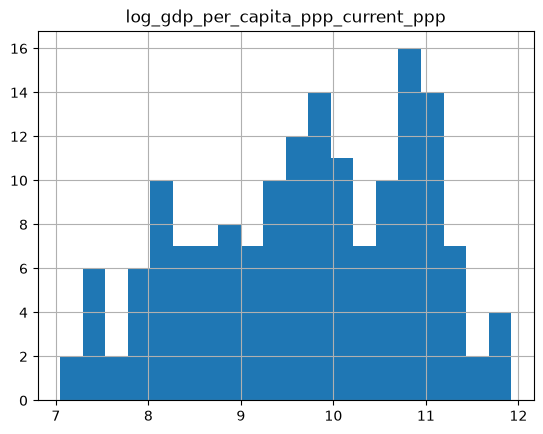

,name,ref_area,log_gdp_per_capita_ppp_current_ppp
100,Luxembourg,LUX,11.921773
144,Singapore,SGP,11.876082
75,Ireland,IRL,11.772845
137,Qatar,QAT,11.770415
123,Norway,NOR,11.548655
29,Switzerland,CHE,11.463122
24,Brunei Darussalam,BRN,11.350790
170,United States,USA,11.318183
122,Netherlands,NLD,11.311160
78,Iceland,ISL,11.309688


,name,ref_area,log_gdp_per_capita_ppp_current_ppp
10,Burundi,BDI,7.047503
27,Central African Republic,CAF,7.136558
148,"Somalia, Fed. Rep.",SOM,7.349623
113,Mozambique,MOZ,7.425591
34,"Congo, Dem. Rep.",COD,7.456236
94,Liberia,LBR,7.492500
104,Madagascar,MDG,7.500224
116,Malawi,MWI,7.512325
119,Niger,NER,7.536446
0,Afghanistan,AFG,7.696995


,count,mean,std,min,25%,50%,75%,max
log_health_exp_per_capita,162.0,6.874996,1.408841,4.064644,5.589946,6.995509,8.044326,9.528071


skew      : -0.14
max / min : 2.3


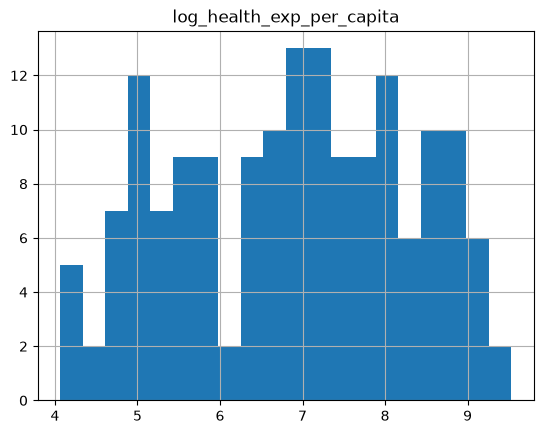

,name,ref_area,log_health_exp_per_capita
170,United States,USA,9.528071
29,Switzerland,CHE,9.316767
123,Norway,NOR,9.187302
100,Luxembourg,LUX,9.072352
75,Ireland,IRL,9.051008
42,Germany,DEU,9.038220
8,Austria,AUT,9.012184
122,Netherlands,NLD,8.991582
11,Belgium,BEL,8.958393
153,Sweden,SWE,8.951667


,name,ref_area,log_health_exp_per_capita
148,"Somalia, Fed. Rep.",SOM,4.064644
104,Madagascar,MDG,4.127098
34,"Congo, Dem. Rep.",COD,4.155323
142,Sudan,SDN,4.234525
119,Niger,NER,4.329735
52,Ethiopia,ETH,4.452023
62,"Gambia, The",GMB,4.555331
10,Burundi,BDI,4.650026
71,Haiti,HTI,4.654512
116,Malawi,MWI,4.784265


,count,mean,std,min,25%,50%,75%,max
log_co2_emissions_per_capita_t,162.0,0.695648,1.431047,-3.073089,-0.274566,0.997417,1.747209,3.8845


skew      : -0.48
max / min : undefined (min = -3.07308859280222)


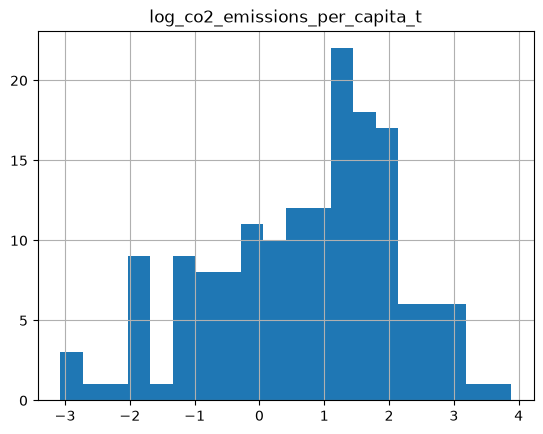

,name,ref_area,log_co2_emissions_per_capita_t
137,Qatar,QAT,3.884500
16,Bahrain,BHR,3.199994
91,Kuwait,KWT,3.122242
24,Brunei Darussalam,BRN,3.051313
163,Trinidad and Tobago,TTO,2.980973
127,Oman,OMN,2.942336
141,Saudi Arabia,SAU,2.936729
3,United Arab Emirates,ARE,2.911289
28,Canada,CAN,2.650424
7,Australia,AUS,2.650398


,name,ref_area,log_co2_emissions_per_capita_t
148,"Somalia, Fed. Rep.",SOM,-3.073089
34,"Congo, Dem. Rep.",COD,-2.846571
27,Central African Republic,CAF,-2.740579
10,Burundi,BDI,-2.668445
119,Niger,NER,-2.112734
104,Madagascar,MDG,-1.915494
52,Ethiopia,ETH,-1.912112
156,Chad,TCD,-1.893354
94,Liberia,LBR,-1.878429
63,Guinea-Bissau,GNB,-1.877808


,count,mean,std,min,25%,50%,75%,max
log_pm2_5_exposure_mcg_m3,162.0,2.975124,0.640131,1.518777,2.596382,2.977527,3.443716,4.679893


skew      : -0.03
max / min : 3.1


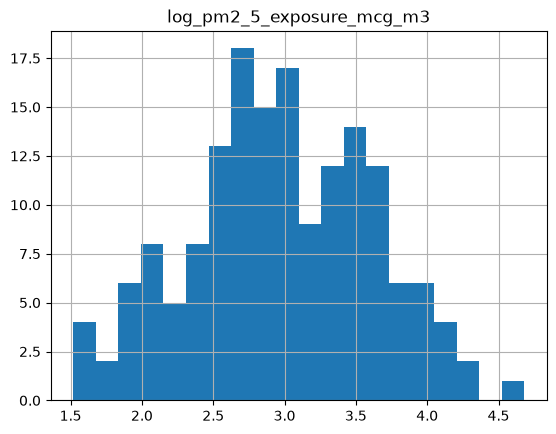

,name,ref_area,log_pm2_5_exposure_mcg_m3
137,Qatar,QAT,4.679893
141,Saudi Arabia,SAU,4.297530
14,Bangladesh,BGD,4.237760
120,Nigeria,NGA,4.185717
119,Niger,NER,4.177924
91,Kuwait,KWT,4.132739
128,Pakistan,PAK,4.066879
3,United Arab Emirates,ARE,4.046322
16,Bahrain,BHR,4.035399
33,Cameroon,CMR,4.018248


,name,ref_area,log_pm2_5_exposure_mcg_m3
53,Finland,FIN,1.518777
78,Iceland,ISL,1.595940
153,Sweden,SWE,1.660013
17,"Bahamas, The",BHS,1.664289
123,Norway,NOR,1.708633
51,Estonia,EST,1.778074
7,Australia,AUS,1.858598
54,Fiji,FJI,1.863882
28,Canada,CAN,1.879525
126,New Zealand,NZL,1.928820


In [5]:
for col in COLUMNS_WITH_LOG:
    describe_feature(df_log, f"log_{col}", bins=20, n_top=10, n_bottom=10)

**Observation.** After log, all four features have |skew| < 0.5. log(CO₂/cap) is the most skewed (−0.48), because of a left tail (SOM, COD, CAF, BDI, NER).

**Conclusion.** The log transform is validated for the four features. The left tail of CO₂ is checked below.

### Check: are the lowest-CO₂ countries a real group or an artifact?


In [6]:
df_log.nsmallest(5, "log_co2_emissions_per_capita_t")[["name", "ref_area", "log_co2_emissions_per_capita_t"]]

,name,ref_area,log_co2_emissions_per_capita_t
148,"Somalia, Fed. Rep.",SOM,-3.073089
34,"Congo, Dem. Rep.",COD,-2.846571
27,Central African Republic,CAF,-2.740579
10,Burundi,BDI,-2.668445
119,Niger,NER,-2.112734


In [7]:
#log_co2_emissions_per_capita_t
FEATURES = [
 'gdp_per_capita_ppp_current_ppp',
 'life_expectancy_yr',
 'co2_emissions_per_capita_t',
 'pm2_5_exposure_mcg_m3',
 'urban_population_percentage_pt',
 'health_expenditure_percentage_of_gdp_pt_gdp',
 'health_exp_per_capita',
 'log_gdp_per_capita_ppp_current_ppp',
 'log_health_exp_per_capita',
 'log_co2_emissions_per_capita_t',
 'log_pm2_5_exposure_mcg_m3']

df_tail = df_log.nsmallest(5, "log_co2_emissions_per_capita_t")[["name", "ref_area", "log_co2_emissions_per_capita_t"]]
df_z_score = pd.DataFrame(columns=df_tail["name"].tolist(),index=FEATURES)
for name in df_z_score.columns:
    z_score = []
    for feature in FEATURES:
        mean = df_log[feature].mean()
        sigma = df_log[feature].std()
        z_score.append((df_log.loc[df_log['name'] == name, feature].values[0] - mean) /sigma)
        
    df_z_score[name] = z_score
    
    print(f"mean z score on all features : {sum(z_score)/len(z_score)}")

display(df_z_score)

mean z score on all features : -1.162134007766449
mean z score on all features : -0.945877724269112
mean z score on all features : -0.7731579949138697
mean z score on all features : -0.8260568272692239
mean z score on all features : -0.737552453030998


,"Somalia, Fed. Rep.","Congo, Dem. Rep.",Central African Republic,Burundi,Niger
gdp_per_capita_ppp_current_ppp,-0.929059,-0.923222,-0.939016,-0.942589,-0.918401
life_expectancy_yr,-1.973790,-1.550675,-2.167277,-1.309367,-1.648518
co2_emissions_per_capita_t,-0.736905,-0.734926,-0.733835,-0.733023,-0.724352
pm2_5_exposure_mcg_m3,-0.335230,0.739351,0.582159,0.731842,2.569558
urban_population_percentage_pt,-0.324485,-0.772558,-0.803848,-1.734788,-2.002947
health_expenditure_percentage_of_gdp_pt_gdp,-0.994586,-1.015590,1.458206,0.904285,-0.886408
health_exp_per_capita,-0.809302,-0.807198,-0.780489,-0.791664,-0.802573
log_gdp_per_capita_ppp_current_ppp,-1.965566,-1.876405,-2.143754,-2.218231,-1.809325
log_health_exp_per_capita,-1.994798,-1.930433,-1.403657,-1.579291,-1.806635
log_co2_emissions_per_capita_t,-2.633551,-2.475263,-2.401197,-2.350791,-1.962466


**Observation.** The 5 lowest-CO₂ countries have negative z-scores on all development features (GDP, life expectancy, urbanization, health/cap). Two exceptions: health % of GDP (e.g. +1.45 for CAF, ratio effect: small GDP, externally funded health) and PM2.5 (e.g. +1.87 for NER, likely desert dust).

**Conclusion.** The tail is a real poverty profile, not an error: these countries are kept. Health % and PM2.5 carry information distinct from development (input for the feature selection).

### The histogram of log(health/cap) shows a gap 

**Observation.** The histogram of log(health/cap) shows a gap that persists across bin sizes: a possible two-group structure (not proven).

**Conclusion.** No action: health/cap is removed from the active features (see block conclusion).

# Correlation study

## Spearman correlation matrix

Computed on the features as they will enter the distance (log where decided). Spearman works on ranks and the log is strictly increasing, so the matrix would be identical on raw columns.

In [8]:
CORRELATION_COLUMNS = {
    "log_gdp_per_capita_ppp_current_ppp": "log(GDP/cap)",
    "log_health_exp_per_capita": "log(Health/cap)",
    "health_expenditure_percentage_of_gdp_pt_gdp": "Health % GDP",
    "life_expectancy_yr": "Life exp.",
    "log_co2_emissions_per_capita_t": "log(CO2/cap)",
    "log_pm2_5_exposure_mcg_m3": "log(PM2.5)",
    "urban_population_percentage_pt": "Urban %",
}

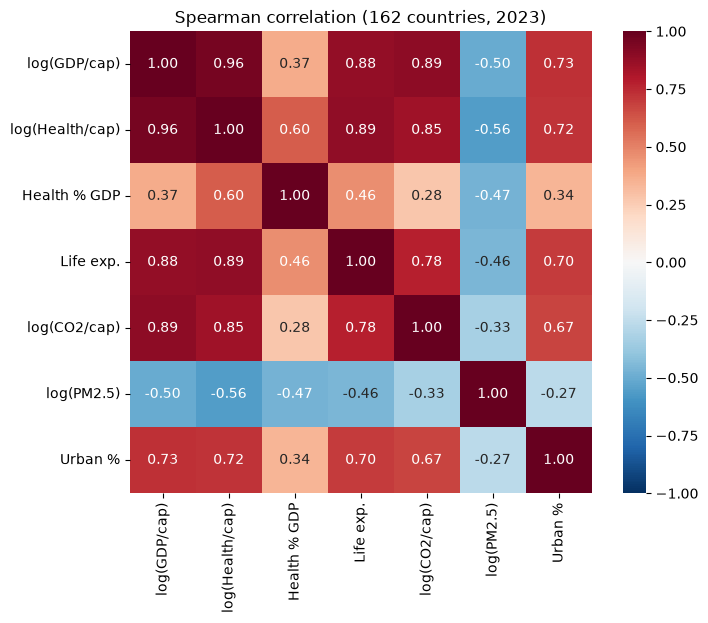

In [9]:
spearman = df_log[list(CORRELATION_COLUMNS)].rename(columns=CORRELATION_COLUMNS).corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation (162 countries, 2023)")
plt.show()

## Pearson correlation matrix

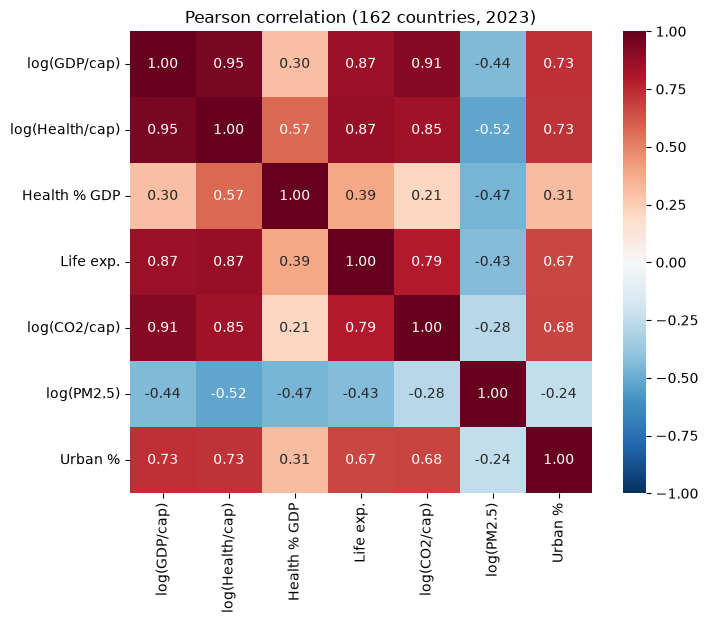

In [10]:
pearson = df_log[list(CORRELATION_COLUMNS)].rename(columns=CORRELATION_COLUMNS).corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson correlation (162 countries, 2023)")
plt.show()

## Pearson - Spearman

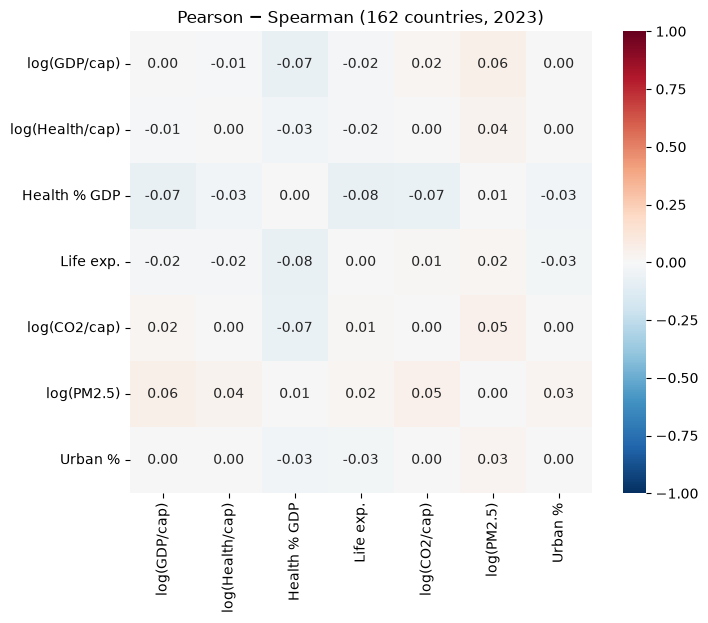

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pearson - spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson − Spearman (162 countries, 2023)")
plt.show()

**Observation.** |Pearson − Spearman| ≤ 0.08 for every pair.

**Conclusion.** On the transformed scale, relationships are roughly linear and no single country drives the correlations: Pearson can be read safely.

# Visualization of correlations

In [12]:
def plot_scatter(df, x, y, annotate=None):
    """Scatter plot of y against x, with Pearson and Spearman in the title and optional country labels."""
    pearson_r = df[x].corr(df[y], method="pearson")
    spearman_r = df[x].corr(df[y], method="spearman")

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(df[x], df[y], s=15, alpha=0.6)
    ax.set_xlabel(CORRELATION_COLUMNS.get(x, x))
    ax.set_ylabel(CORRELATION_COLUMNS.get(y, y))
    ax.set_title(f"Pearson = {pearson_r:.2f} | Spearman = {spearman_r:.2f} ({len(df)} countries)")

    # Label selected countries by ISO code to locate extreme points
    points = df.set_index("ref_area")
    for ref_area in annotate or []:
        ax.annotate(ref_area, (points.loc[ref_area, x], points.loc[ref_area, y]), fontsize=8)

    plt.show()

### log(health/cap) vs log(GDP/cap): near-straight line expected (redundancy)

Spearman = 0.96
Pearson = 0.95

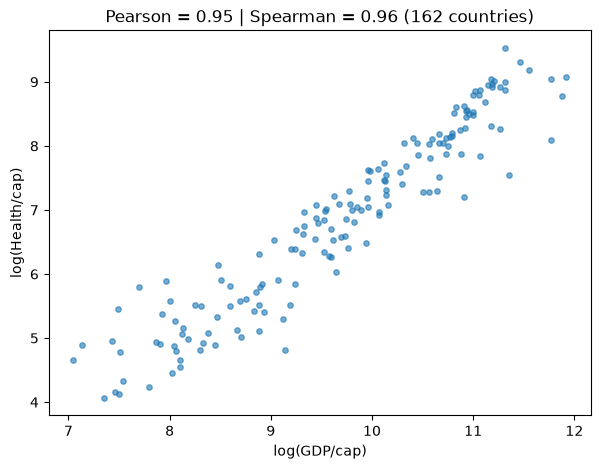

In [13]:
plot_scatter(df_log, "log_gdp_per_capita_ppp_current_ppp", "log_health_exp_per_capita")

**Observation.** Spearman 0.96, Pearson 0.95, almost straight line. This is largely by construction: health/cap = health % × GDP/cap.

**Conclusion.** Redundant with GDP/cap: health/cap is removed. Given GDP, its only extra information is health %, treated separately.

**Important Decision :** health/cap is removed  

### Health % of GDP vs log(GDP/cap): scattered cloud expected (the ambiguous feature)

Spearman = 0.37
Pearson = 0.30

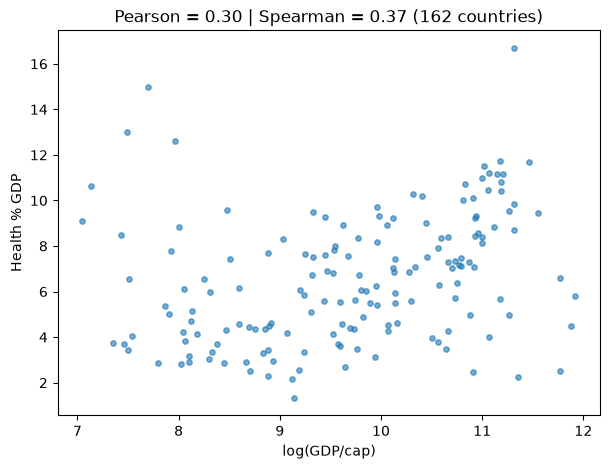

In [14]:
plot_scatter(df_log, "log_gdp_per_capita_ppp_current_ppp", "health_expenditure_percentage_of_gdp_pt_gdp")

**Observation.** Weak positive relationship (Spearman 0.37, Pearson 0.30), very dispersed cloud with no clear line or curve.

**Conclusion.** Health % carries information distinct from GDP. It is removed from the main version for validity reasons (ambiguous meaning), not redundancy; kept as a variant for the clustering stage.

**Important decision : It is removed from the main version for validity reasons (ambiguous meaning)**


**Why it is ambiguous**
- It is a ratio (health spending / total GDP): its value depends as much on GDP as on spending.
- The same value means opposite things: a developed health system (USA, Germany, Switzerland) or a tiny economy funded from abroad (Liberia, Afghanistan, Tuvalu; hypothesis, not verified).
- Equally poor countries sit at both extremes (Afghanistan, Liberia at the top; Laos, Bangladesh at the bottom).
- Oil-inflated GDP lowers the ratio (Qatar, Brunei), even when spending per capita is high.
- Spearman with GDP per capita is only 0.37, so the ratio does not follow wealth.
- In the lowest-CO₂ check, Central African Republic (+1.45) and Burundi (+0.9) are high on this feature while low on all others.

**Why we remove it**
- It is ambiguous, hence noisy, and standardization gives noise the same weight as signal.
- Health is already covered by life expectancy, an outcome rather than a spending effort.

**Consequence**: health spending no longer appears in the main version

### log(CO₂/cap) vs log(GDP/cap): strong link expected (Kaya identity)

Spearman = 0.89
Pearson = 0.91

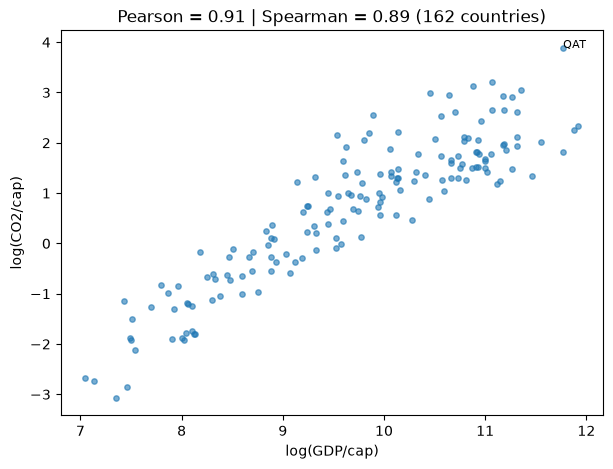

In [15]:
# GDP on x: by convention, the explanatory variable goes on the horizontal axis
plot_scatter(df_log, "log_gdp_per_capita_ppp_current_ppp", "log_co2_emissions_per_capita_t", annotate=["QAT"])

**Observation.** Strong relationship (Spearman 0.89, Pearson 0.91), consistent with the Kaya identity: CO₂/cap = GDP/cap × CO₂/GDP. Qatar sits above the trend.

**Conclusion.** CO₂/cap is kept (conceptually distinct: emissions), but it largely duplicates the development axis. Alternative to consider: carbon intensity (CO₂/GDP).

### log(CO₂/cap) vs log(PM2.5): weak link expected

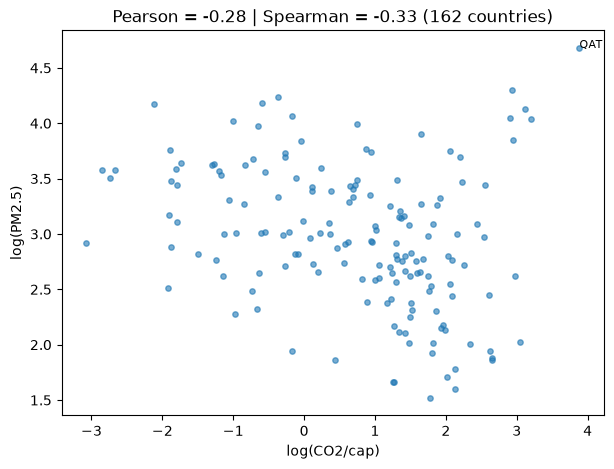

In [16]:
plot_scatter(df_log, "log_co2_emissions_per_capita_t", "log_pm2_5_exposure_mcg_m3", annotate=["QAT"])

**Observation.** Weak negative correlation (Spearman −0.33, Pearson −0.28). Controlling for GDP (partial correlation), it becomes positive (+0.33): the raw negative sign comes from GDP (rich countries: more CO₂, cleaner air).

**Conclusion.** Both features are kept. Their link is mediated by development; to revisit before interpreting clusters.

In [17]:
def regression_residuals(df, x, y):
    """Residuals of the linear regression of y on x: the part of y not explained by x."""
    a, b = np.polyfit(df[x], df[y], deg=1)
    residuals = df[y] - (b + a * df[x])
    return residuals

In [18]:
residuals_log_co2_cap = regression_residuals(df_log, "log_gdp_per_capita_ppp_current_ppp", "log_co2_emissions_per_capita_t")
residuals_log_pm25 = regression_residuals(df_log, "log_gdp_per_capita_ppp_current_ppp", "log_pm2_5_exposure_mcg_m3")

# Partial correlation: correlation of the residuals, i.e. at equal GDP
partial_pearson = residuals_log_co2_cap.corr(residuals_log_pm25, method="pearson")
partial_spearman = residuals_log_co2_cap.corr(residuals_log_pm25, method="spearman")
print(f"Partial Pearson  : {partial_pearson:.2f}")
print(f"Partial Spearman : {partial_spearman:.2f}")

Partial Pearson  : 0.33
Partial Spearman : 0.30


**Observation.** At equal GDP (residuals of log CO₂ and log PM2.5 regressed on log GDP), the correlation is positive: Pearson +0.33, Spearman +0.30.

**Conclusion.** The raw negative correlation is created by GDP (confounder). At equal wealth, more CO₂ goes with more PM2.5.

## Conclusion: feature selection decisions

**Main version: 5 active features** (162 countries, 2023)
- log GDP per capita (PPP)
- life expectancy
- log CO₂ per capita
- log PM2.5
- urbanization (% of population)

**Removed**
- **Health spending per capita**: built from GDP per capita (Spearman 0.96); once GDP is known, it only adds the information of health % of GDP.
- **Health spending (% of GDP)**: ambiguous (same value, opposite situations), hence noisy; health is already covered by life expectancy. Kept as a **variant for the clustering stage**.

**Kept despite correlations** (Spearman 0.67 to 0.89): GDP, life expectancy, CO₂, urbanization describe distinct concepts. Known risk: clusters may mostly split a poor → rich axis. To check with a variant without one of them, and with PCA.

**CO₂ vs PM2.5**: raw correlation −0.33, but +0.33 at equal wealth (GDP is a confounder). The two features stay: weakly redundant.

**Next** (notebook 06): |z| > 2.5 check after standardization, extremes after log, and variants.